In [ ]:
# # Healthcare Data Analytics — Python Analysis

# ## Objective

# This notebook explores hospital data stored in a relational SQL Server database.

# The objective is not only to visualize the data, but to:

# - inspect the structure and quality of the data
# - identify missing, duplicate, and inconsistent records
# - understand patient and admission patterns
# - analyze hospital utilization
# - examine treatment activity
# - analyze billing and revenue
# - investigate relationships between operational and financial metrics

# ## Why Python?

# SQL Server provides the structured data foundation, while Python is used as the analytical layer.

# Python allows us to:

# - inspect data programmatically
# - perform statistical analysis
# - identify outliers and unusual patterns
# - examine distributions
# - calculate relationships between variables
# - create exploratory visualizations

# The findings from this analysis will later support the interactive dashboards created in Excel and Power BI.

In [ ]:
# ## 1. Import Required Libraries

# The main libraries used in this analysis are:

# - pandas → data manipulation and analysis
# - numpy → numerical operations
# - matplotlib → visualization
# - seaborn → statistical visualization
# - sqlalchemy → connection between Python and SQL Server

In [ ]:
# Install packages if required.
# If these packages are already installed, you can skip this cell.

%pip install pandas numpy matplotlib seaborn sqlalchemy pyodbc

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine
from urllib.parse import quote_plus

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ## 2. Connect to SQL Server

# SQL Server is treated as the source of truth for this project.

# Instead of exporting the Excel dashboard and then analyzing the exported file, Python connects directly to the original database.

# This keeps the analytical workflow independent of the presentation layer.

# Update the server and database names below according to the SQL Server instance used for the project.

In [2]:
# SQL Server connection

SERVER = r"HOPE\SQLEXPRESS"
DATABASE = "Healthcare_Analytics"

# For Windows Authentication
connection_string = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={SERVER};"
    f"DATABASE={DATABASE};"
    "Trusted_Connection=yes;"
)

engine = create_engine(
    "mssql+pyodbc:///?odbc_connect=" + quote_plus(connection_string)
)

print("SQLAlchemy engine created successfully.")

SQLAlchemy engine created successfully.


In [3]:
# Test the SQL Server connection

test_query = "SELECT GETDATE() AS Current_SQL_Server_Time;"

test_df = pd.read_sql_query(test_query, engine)

test_df

,Current_SQL_Server_Time
0,2026-09-19 22:53:55.770


In [ ]:
# ## 3. Load Analysis-Ready Datasets

# The database is normalized into multiple related tables.

# For Python analysis, we do not need to flatten the entire database into one giant table.

# Instead, we create focused analytical datasets using SQL JOINs.

# Three datasets will be used:

# 1. Patient & Admission Analysis
# 2. Clinical / Treatment Analysis
# 3. Financial Analysis

# This demonstrates an important principle:

# > Data can be normalized for storage and integrity, then joined when it is needed for analysis.

In [4]:
# Patient and Admission Analysis Dataset

patient_admission_query = """
SELECT
    p.Patient_ID,
    p.Patient_Name,
    p.Gender,
    p.Date_of_Birth,
    p.Blood_Group,
    p.Registration_Date,

    a.Admission_ID,
    a.Admission_Date,
    a.Discharge_Date,
    a.Admission_Type,
    a.Department,
    a.Primary_Doctor_ID,

    d.Doctor_Name,
    d.Specialization,
    d.Experience_Years

FROM Healthcare.Patients AS p

INNER JOIN Healthcare.Admissions AS a
    ON p.Patient_ID = a.Patient_ID

LEFT JOIN Healthcare.Doctors AS d
    ON a.Primary_Doctor_ID = d.Doctor_ID;
"""

df_admissions = pd.read_sql_query(
    patient_admission_query,
    engine
)

print("Rows:", df_admissions.shape[0])
print("Columns:", df_admissions.shape[1])

df_admissions.head()

Rows: 30
Columns: 15


,Patient_ID,Patient_Name,Gender,Date_of_Birth,Blood_Group,Registration_Date,Admission_ID,Admission_Date,Discharge_Date,Admission_Type,Department,Primary_Doctor_ID,Doctor_Name,Specialization,Experience_Years
0,P001,Rahul Sharma,Male,1974-05-21,B+,2025-01-15,A001,2025-01-20 09:30:00,2025-01-23 11:00:00,Emergency,Cardiology,D001,Dr. Amit Sharma,Cardiology,15
1,P002,Priya Verma,Female,1988-11-03,O+,2025-01-22,A002,2025-01-25 10:15:00,2025-01-27 15:00:00,Planned,Neurology,D002,Dr. Priya Mehta,Neurology,12
2,P003,Amit Kapoor,Male,1965-07-14,A+,2025-02-05,A003,2025-02-07 08:45:00,2025-02-12 12:30:00,Emergency,Orthopedics,D003,Dr. Rajiv Kapoor,Orthopedics,18
3,P004,Sneha Gupta,Female,1995-02-18,AB+,2025-02-11,A004,2025-02-15 14:00:00,2025-02-16 16:00:00,Planned,Pediatrics,D004,Dr. Neha Verma,Pediatrics,8
4,P005,Vikram Singh,Male,1959-09-27,O-,2025-02-19,A005,2025-02-22 11:30:00,2025-02-28 10:00:00,Emergency,Pulmonology,D009,Dr. Rohit Bansal,Pulmonology,13


In [6]:
# Clinical / Treatment Analysis Dataset

clinical_query = """
SELECT
    a.Admission_ID,
    a.Patient_ID,
    a.Admission_Date,
    a.Department,
    a.Admission_Type,

    pt.Patient_Treatment_ID,
    pt.Treatment_ID,
    pt.Doctor_ID,

    t.Treatment_Name,
    t.Treatment_Category,
    t.Standard_Cost

FROM Healthcare.Admissions AS a

INNER JOIN Healthcare.Patient_Treatment AS pt
    ON a.Admission_ID = pt.Admission_ID

LEFT JOIN Healthcare.Treatments AS t
    ON pt.Treatment_ID = t.Treatment_ID;
"""

df_clinical = pd.read_sql_query(
    clinical_query,
    engine
)

print("Rows:", df_clinical.shape[0])
print("Columns:", df_clinical.shape[1])

df_clinical.head()

Rows: 30
Columns: 11


,Admission_ID,Patient_ID,Admission_Date,Department,Admission_Type,Patient_Treatment_ID,Treatment_ID,Doctor_ID,Treatment_Name,Treatment_Category,Standard_Cost
0,A001,P001,2025-01-20 09:30:00,Cardiology,Emergency,PT001,T001,D001,ECG,Diagnostic,500.00
1,A001,P001,2025-01-20 09:30:00,Cardiology,Emergency,PT002,T002,D001,Echocardiogram,Diagnostic,"2,500.00"
2,A002,P002,2025-01-25 10:15:00,Neurology,Planned,PT003,T003,D002,MRI Scan,Diagnostic,"6,000.00"
3,A003,P003,2025-02-07 08:45:00,Orthopedics,Emergency,PT004,T005,D003,X-Ray,Diagnostic,800.00
4,A003,P003,2025-02-07 08:45:00,Orthopedics,Emergency,PT005,T007,D003,Physiotherapy,Therapy,"1,200.00"


In [7]:
# Financial Analysis Dataset

financial_query = """
SELECT
    a.Admission_ID,
    a.Patient_ID,
    a.Admission_Date,
    a.Discharge_Date,
    a.Department,
    a.Admission_Type,

    b.Bill_ID,
    b.Billing_Date,
    b.Treatment_Charges,
    b.Medicine_Charges,
    b.Room_Charges,
    b.Doctor_Charges,
    b.Other_Charges,
    b.Gross_Amount,
    b.Discount_Percentage,
    b.Discount_Amount,
    b.Insurance_Coverage,
    b.Net_Amount,
    b.Payment_Status,
    b.Payment_Method

FROM Healthcare.Admissions AS a

LEFT JOIN Healthcare.Billing AS b
    ON a.Admission_ID = b.Admission_ID;
"""

df_financial = pd.read_sql_query(
    financial_query,
    engine
)

print("Rows:", df_financial.shape[0])
print("Columns:", df_financial.shape[1])

df_financial.head()

Rows: 30
Columns: 20


,Admission_ID,Patient_ID,Admission_Date,Discharge_Date,Department,Admission_Type,Bill_ID,Billing_Date,Treatment_Charges,Medicine_Charges,Room_Charges,Doctor_Charges,Other_Charges,Gross_Amount,Discount_Percentage,Discount_Amount,Insurance_Coverage,Net_Amount,Payment_Status,Payment_Method
0,A001,P001,2025-01-20 09:30:00,2025-01-23 11:00:00,Cardiology,Emergency,BL001,2025-01-23,"3,000.00",450.00,"12,000.00","1,500.00",500.00,"17,450.00",5.00,872.50,"13,200.00","3,377.50",Paid,Insurance
1,A002,P002,2025-01-25 10:15:00,2025-01-27 15:00:00,Neurology,Planned,BL002,2025-01-27,"6,000.00",300.00,"5,000.00","1,300.00",300.00,"12,900.00",0.00,0.00,"10,320.00","2,580.00",Paid,Insurance
2,A003,P003,2025-02-07 08:45:00,2025-02-12 12:30:00,Orthopedics,Emergency,BL003,2025-02-12,"2,000.00",600.00,"20,000.00","1,600.00",500.00,"24,700.00",5.00,"1,235.00","18,772.00","4,693.00",Paid,Insurance
3,A004,P004,2025-02-15 14:00:00,2025-02-16 16:00:00,Pediatrics,Planned,BL004,2025-02-16,900.00,250.00,"1,500.00","1,000.00",200.00,"3,850.00",0.00,0.00,"3,080.00",770.00,Paid,Insurance
4,A005,P005,2025-02-22 11:30:00,2025-02-28 10:00:00,Pulmonology,Emergency,BL005,2025-02-28,"1,500.00",900.00,"54,000.00","1,350.00",800.00,"58,550.00",5.00,"2,927.50","45,618.00","10,004.50",Paid,Insurance


In [ ]:
# # 4. Initial Data Inspection

# Before cleaning or visualization, we need to understand what we actually received from the database.

# The first inspection checks:

# - number of rows and columns
# - column names
# - data types
# - sample records
# - missing values
# - duplicate records

In [8]:
# Overview of all three datasets

datasets = {
    "Patient & Admission": df_admissions,
    "Clinical": df_clinical,
    "Financial": df_financial
}

for name, df in datasets.items():
    print("=" * 70)
    print(name)
    print("Shape:", df.shape)
    print()
    print("Columns:")
    print(df.columns.tolist())
    print()

Patient & Admission
Shape: (30, 15)

Columns:
['Patient_ID', 'Patient_Name', 'Gender', 'Date_of_Birth', 'Blood_Group', 'Registration_Date', 'Admission_ID', 'Admission_Date', 'Discharge_Date', 'Admission_Type', 'Department', 'Primary_Doctor_ID', 'Doctor_Name', 'Specialization', 'Experience_Years']

Clinical
Shape: (30, 11)

Columns:
['Admission_ID', 'Patient_ID', 'Admission_Date', 'Department', 'Admission_Type', 'Patient_Treatment_ID', 'Treatment_ID', 'Doctor_ID', 'Treatment_Name', 'Treatment_Category', 'Standard_Cost']

Financial
Shape: (30, 20)

Columns:
['Admission_ID', 'Patient_ID', 'Admission_Date', 'Discharge_Date', 'Department', 'Admission_Type', 'Bill_ID', 'Billing_Date', 'Treatment_Charges', 'Medicine_Charges', 'Room_Charges', 'Doctor_Charges', 'Other_Charges', 'Gross_Amount', 'Discount_Percentage', 'Discount_Amount', 'Insurance_Coverage', 'Net_Amount', 'Payment_Status', 'Payment_Method']



In [9]:
# Inspect data types

print("PATIENT & ADMISSION")
df_admissions.info()

print("\n" + "=" * 70)
print("CLINICAL")
df_clinical.info()

print("\n" + "=" * 70)
print("FINANCIAL")
df_financial.info()

PATIENT & ADMISSION
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Patient_ID         30 non-null     str           
 1   Patient_Name       30 non-null     str           
 2   Gender             30 non-null     str           
 3   Date_of_Birth      30 non-null     object        
 4   Blood_Group        30 non-null     str           
 5   Registration_Date  30 non-null     object        
 6   Admission_ID       30 non-null     str           
 7   Admission_Date     30 non-null     datetime64[us]
 8   Discharge_Date     30 non-null     datetime64[us]
 9   Admission_Type     30 non-null     str           
 10  Department         30 non-null     str           
 11  Primary_Doctor_ID  30 non-null     str           
 12  Doctor_Name        30 non-null     str           
 13  Specialization     30 non-null     str           
 14  Exp

In [10]:
# Preview records

display(df_admissions.head())
display(df_clinical.head())
display(df_financial.head())

,Patient_ID,Patient_Name,Gender,Date_of_Birth,Blood_Group,Registration_Date,Admission_ID,Admission_Date,Discharge_Date,Admission_Type,Department,Primary_Doctor_ID,Doctor_Name,Specialization,Experience_Years
0,P001,Rahul Sharma,Male,1974-05-21,B+,2025-01-15,A001,2025-01-20 09:30:00,2025-01-23 11:00:00,Emergency,Cardiology,D001,Dr. Amit Sharma,Cardiology,15
1,P002,Priya Verma,Female,1988-11-03,O+,2025-01-22,A002,2025-01-25 10:15:00,2025-01-27 15:00:00,Planned,Neurology,D002,Dr. Priya Mehta,Neurology,12
2,P003,Amit Kapoor,Male,1965-07-14,A+,2025-02-05,A003,2025-02-07 08:45:00,2025-02-12 12:30:00,Emergency,Orthopedics,D003,Dr. Rajiv Kapoor,Orthopedics,18
3,P004,Sneha Gupta,Female,1995-02-18,AB+,2025-02-11,A004,2025-02-15 14:00:00,2025-02-16 16:00:00,Planned,Pediatrics,D004,Dr. Neha Verma,Pediatrics,8
4,P005,Vikram Singh,Male,1959-09-27,O-,2025-02-19,A005,2025-02-22 11:30:00,2025-02-28 10:00:00,Emergency,Pulmonology,D009,Dr. Rohit Bansal,Pulmonology,13


,Admission_ID,Patient_ID,Admission_Date,Department,Admission_Type,Patient_Treatment_ID,Treatment_ID,Doctor_ID,Treatment_Name,Treatment_Category,Standard_Cost
0,A001,P001,2025-01-20 09:30:00,Cardiology,Emergency,PT001,T001,D001,ECG,Diagnostic,500.00
1,A001,P001,2025-01-20 09:30:00,Cardiology,Emergency,PT002,T002,D001,Echocardiogram,Diagnostic,"2,500.00"
2,A002,P002,2025-01-25 10:15:00,Neurology,Planned,PT003,T003,D002,MRI Scan,Diagnostic,"6,000.00"
3,A003,P003,2025-02-07 08:45:00,Orthopedics,Emergency,PT004,T005,D003,X-Ray,Diagnostic,800.00
4,A003,P003,2025-02-07 08:45:00,Orthopedics,Emergency,PT005,T007,D003,Physiotherapy,Therapy,"1,200.00"


,Admission_ID,Patient_ID,Admission_Date,Discharge_Date,Department,Admission_Type,Bill_ID,Billing_Date,Treatment_Charges,Medicine_Charges,Room_Charges,Doctor_Charges,Other_Charges,Gross_Amount,Discount_Percentage,Discount_Amount,Insurance_Coverage,Net_Amount,Payment_Status,Payment_Method
0,A001,P001,2025-01-20 09:30:00,2025-01-23 11:00:00,Cardiology,Emergency,BL001,2025-01-23,"3,000.00",450.00,"12,000.00","1,500.00",500.00,"17,450.00",5.00,872.50,"13,200.00","3,377.50",Paid,Insurance
1,A002,P002,2025-01-25 10:15:00,2025-01-27 15:00:00,Neurology,Planned,BL002,2025-01-27,"6,000.00",300.00,"5,000.00","1,300.00",300.00,"12,900.00",0.00,0.00,"10,320.00","2,580.00",Paid,Insurance
2,A003,P003,2025-02-07 08:45:00,2025-02-12 12:30:00,Orthopedics,Emergency,BL003,2025-02-12,"2,000.00",600.00,"20,000.00","1,600.00",500.00,"24,700.00",5.00,"1,235.00","18,772.00","4,693.00",Paid,Insurance
3,A004,P004,2025-02-15 14:00:00,2025-02-16 16:00:00,Pediatrics,Planned,BL004,2025-02-16,900.00,250.00,"1,500.00","1,000.00",200.00,"3,850.00",0.00,0.00,"3,080.00",770.00,Paid,Insurance
4,A005,P005,2025-02-22 11:30:00,2025-02-28 10:00:00,Pulmonology,Emergency,BL005,2025-02-28,"1,500.00",900.00,"54,000.00","1,350.00",800.00,"58,550.00",5.00,"2,927.50","45,618.00","10,004.50",Paid,Insurance


In [ ]:
# # 5. Data Quality Assessment

# Before performing analysis, we check whether the datasets contain:

# - missing values
# - duplicate records
# - invalid dates
# - impossible length of stay
# - invalid numeric values
# - suspicious financial values

# This step is important because analytical conclusions are only useful when the underlying data is reasonably reliable.

In [11]:
# Missing value summary

def missing_summary(df, name):
    summary = pd.DataFrame({
        "Missing Count": df.isnull().sum(),
        "Missing %": df.isnull().mean() * 100
    })

    summary = summary[summary["Missing Count"] > 0]
    
    print(f"\n{name}")
    if summary.empty:
        print("No missing values found.")
    else:
        display(summary.sort_values("Missing Count", ascending=False))


for name, df in datasets.items():
    missing_summary(df, name)


Patient & Admission
No missing values found.

Clinical
No missing values found.

Financial
No missing values found.


In [12]:
# Duplicate record checks

for name, df in datasets.items():
    print(f"{name}:")
    print("Total rows:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print()

Patient & Admission:
Total rows: 30
Duplicate rows: 0

Clinical:
Total rows: 30
Duplicate rows: 0

Financial:
Total rows: 30
Duplicate rows: 0



In [ ]:
# ## Date and Length-of-Stay Validation

# For hospital admissions:

# Admission Date should not occur after Discharge Date.

# Length of Stay is calculated as:

# Discharge Date - Admission Date

# This is an important operational metric because unusually long 
# or negative stays can indicate data-quality problems or exceptional cases that require investigation.

In [13]:
# Convert date columns to datetime

date_columns_admissions = [
    "Date_of_Birth",
    "Registration_Date",
    "Admission_Date",
    "Discharge_Date"
]

for col in date_columns_admissions:
    df_admissions[col] = pd.to_datetime(
        df_admissions[col],
        errors="coerce"
    )

df_financial["Admission_Date"] = pd.to_datetime(
    df_financial["Admission_Date"],
    errors="coerce"
)

df_financial["Discharge_Date"] = pd.to_datetime(
    df_financial["Discharge_Date"],
    errors="coerce"
)

df_financial["Billing_Date"] = pd.to_datetime(
    df_financial["Billing_Date"],
    errors="coerce"
)

df_clinical["Admission_Date"] = pd.to_datetime(
    df_clinical["Admission_Date"],
    errors="coerce"
)

print("Date conversion completed.")

Date conversion completed.


In [14]:
# Calculate Length of Stay

df_admissions["Length_of_Stay"] = (
    df_admissions["Discharge_Date"]
    - df_admissions["Admission_Date"]
).dt.days

# Identify problematic stays

problematic_stays = df_admissions[
    df_admissions["Length_of_Stay"] < 0
]

print("Problematic Length-of-Stay records:", len(problematic_stays))

if len(problematic_stays) > 0:
    display(problematic_stays[
        [
            "Admission_ID",
            "Patient_ID",
            "Admission_Date",
            "Discharge_Date",
            "Length_of_Stay"
        ]
    ])

Problematic Length-of-Stay records: 0


In [16]:
# Calculate patient age

today = pd.Timestamp.today()

df_admissions["Age"] = (
    (today - df_admissions["Date_of_Birth"]).dt.days / 365.25
).round().astype("Int64")

# Create age groups

bins = [-1, 17, 29, 44, 59, np.inf]

labels = [
    "Under 18",
    "18-29",
    "30-44",
    "45-59",
    "60+"
]

df_admissions["Age_Group"] = pd.cut(
    df_admissions["Age"],
    bins=bins,
    labels=labels
)

df_admissions[
    ["Patient_ID", "Date_of_Birth", "Age", "Age_Group"]
].head(10)

,Patient_ID,Date_of_Birth,Age,Age_Group
0,P001,1974-05-21,52,45-59
1,P002,1988-11-03,38,30-44
2,P003,1965-07-14,61,60+
3,P004,1995-02-18,32,30-44
4,P005,1959-09-27,67,60+
5,P006,1982-06-09,44,30-44
6,P007,1990-12-15,36,30-44
7,P008,1978-04-26,48,45-59
8,P009,1955-01-08,72,60+
9,P010,1969-10-19,57,45-59


In [ ]:
# # 6. Descriptive Statistics

# Descriptive statistics help us understand the numerical characteristics of the data before creating visualizations.

# We will examine:

# - count
# - mean
# - standard deviation
# - minimum
# - quartiles
# - maximum

# For hospital data, this is particularly useful for:

# - age
# - length of stay
# - treatment cost
# - gross billing
# - net billing
# - insurance coverage

In [18]:
# Descriptive statistics for patient/admission data

df_admissions[
    [
        "Age",
        "Length_of_Stay",
        "Experience_Years"
    ]
].describe()

,Age,Length_of_Stay,Experience_Years
count,30.00,30.00,30.00
mean,49.53,3.00,12.67
std,12.69,1.78,3.61
min,28.00,1.00,7.00
25%,38.75,2.00,10.00
50%,49.00,2.50,13.00
75%,60.00,4.00,14.75
max,72.00,9.00,20.00


In [19]:
# Descriptive statistics for financial data

financial_numeric = [
    "Treatment_Charges",
    "Medicine_Charges",
    "Room_Charges",
    "Doctor_Charges",
    "Other_Charges",
    "Gross_Amount",
    "Discount_Amount",
    "Insurance_Coverage",
    "Net_Amount"
]

df_financial[financial_numeric].describe()

,Treatment_Charges,Medicine_Charges,Room_Charges,Doctor_Charges,Other_Charges,Gross_Amount,Discount_Amount,Insurance_Coverage,Net_Amount
count,30.00,30.00,30.00,30.00,30.00,30.00,30.00,30.00,30.00
mean,"2,403.33",491.67,"18,866.67","1,361.67",390.00,"23,513.33",803.17,"18,350.15","4,526.68"
std,"2,110.81",251.58,"18,839.13",249.72,196.26,"20,561.72","1,178.72","15,582.30","4,596.12"
min,500.00,250.00,"1,500.00",900.00,200.00,"3,850.00",0.00,"3,080.00",770.00
25%,"1,000.00",300.00,"7,625.00","1,212.50",262.50,"11,250.00",0.00,"9,667.50","1,705.62"
50%,"1,350.00",425.00,"12,000.00","1,350.00",300.00,"14,950.00",198.75,"12,080.00","2,901.25"
75%,"3,875.00",600.00,"23,000.00","1,500.00",500.00,"26,350.00","1,154.38","20,026.00","5,006.50"
max,"7,500.00","1,200.00","81,000.00","2,000.00","1,000.00","92,700.00","4,635.00","70,372.00","22,693.00"


In [ ]:
# # 7. Patient Analysis

# The first analytical question is:

# ## Who are the patients?

# We will examine:

# - age distribution
# - gender composition
# - age groups

# These analyses provide demographic context before moving into hospital operations and finance.

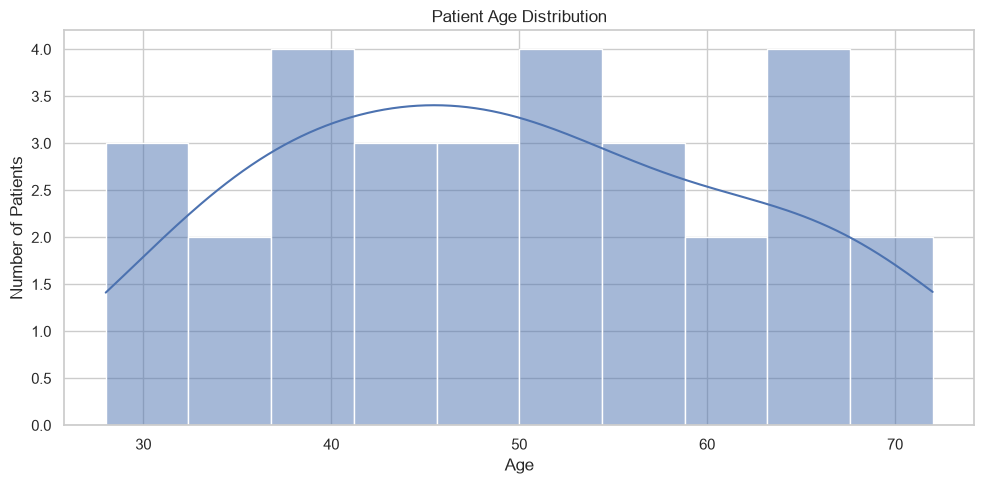

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_admissions,
    x="Age",
    bins=10,
    kde=True
)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

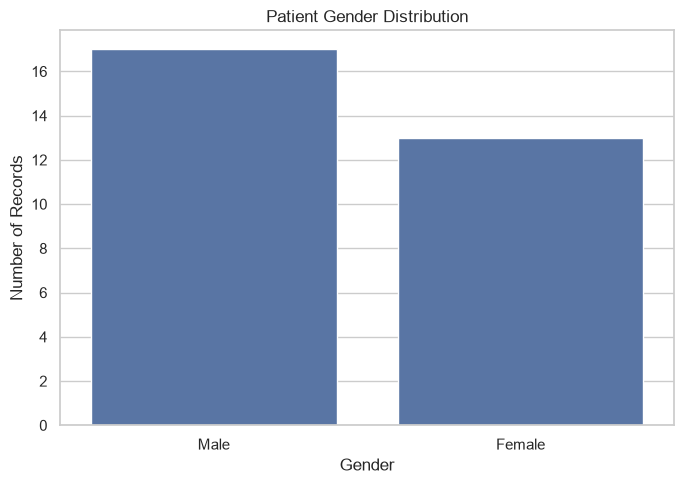

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_admissions,
    x="Gender"
)

plt.title("Patient Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

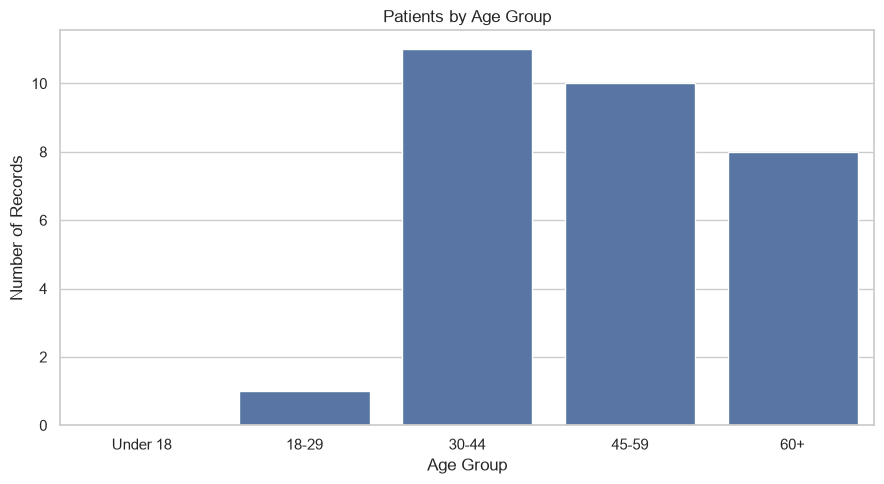

In [22]:
age_group_counts = (
    df_admissions["Age_Group"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

plt.title("Patients by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# # 8. Hospital Utilization Analysis

# The next question is:

# ## How is the hospital being utilized?

# We will analyze:

# - admissions by department
# - admission type
# - admission trend
# - length of stay

# These metrics describe the operational activity of the hospital.

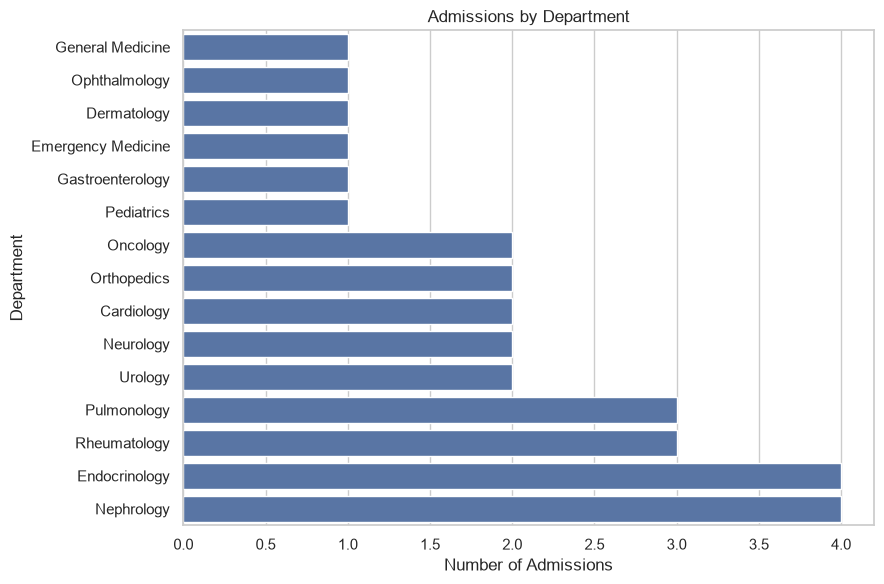

In [23]:
department_counts = (
    df_admissions["Department"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=department_counts.values,
    y=department_counts.index
)

plt.title("Admissions by Department")
plt.xlabel("Number of Admissions")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

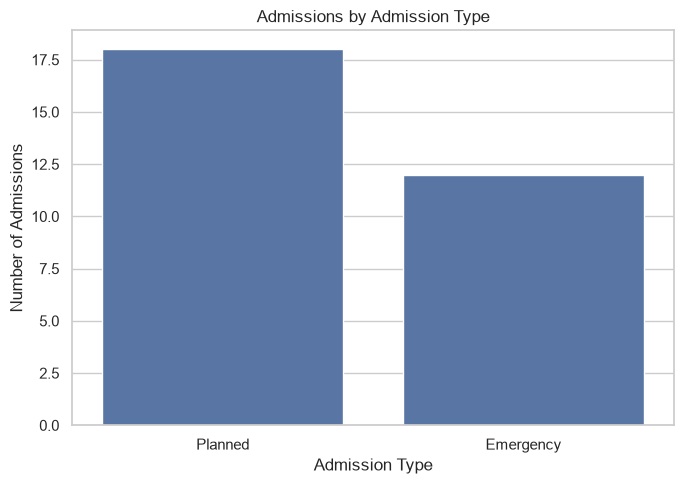

In [24]:
admission_type_counts = (
    df_admissions["Admission_Type"]
    .value_counts()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=admission_type_counts.index,
    y=admission_type_counts.values
)

plt.title("Admissions by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Admissions")
plt.tight_layout()
plt.show()

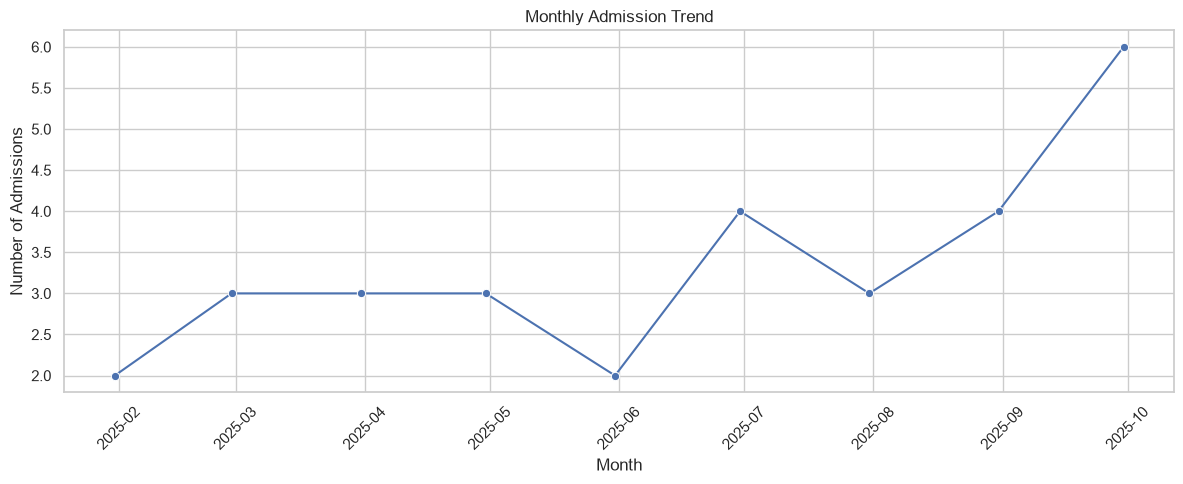

In [25]:
monthly_admissions = (
    df_admissions
    .set_index("Admission_Date")
    .resample("ME")
    .size()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_admissions.index,
    y=monthly_admissions.values,
    marker="o"
)

plt.title("Monthly Admission Trend")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

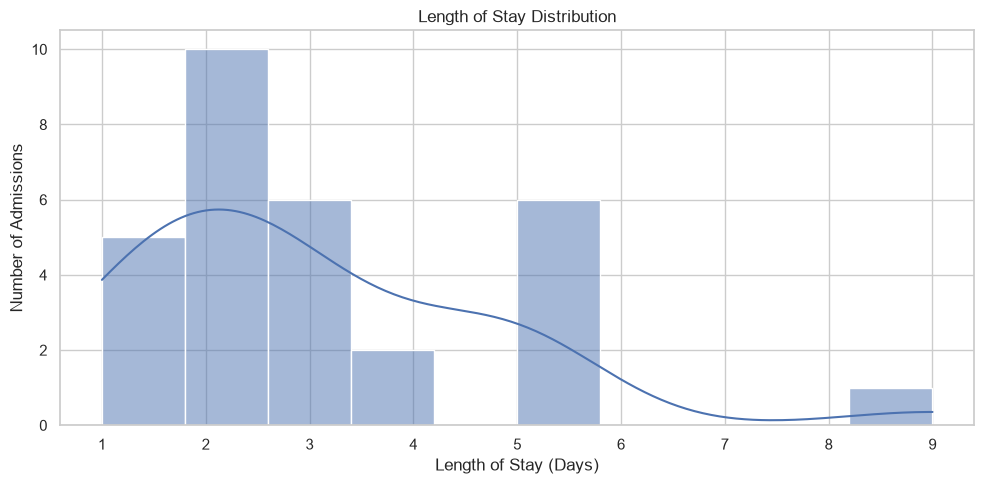

In [26]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_admissions,
    x="Length_of_Stay",
    bins=10,
    kde=True
)

plt.title("Length of Stay Distribution")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Number of Admissions")
plt.tight_layout()
plt.show()

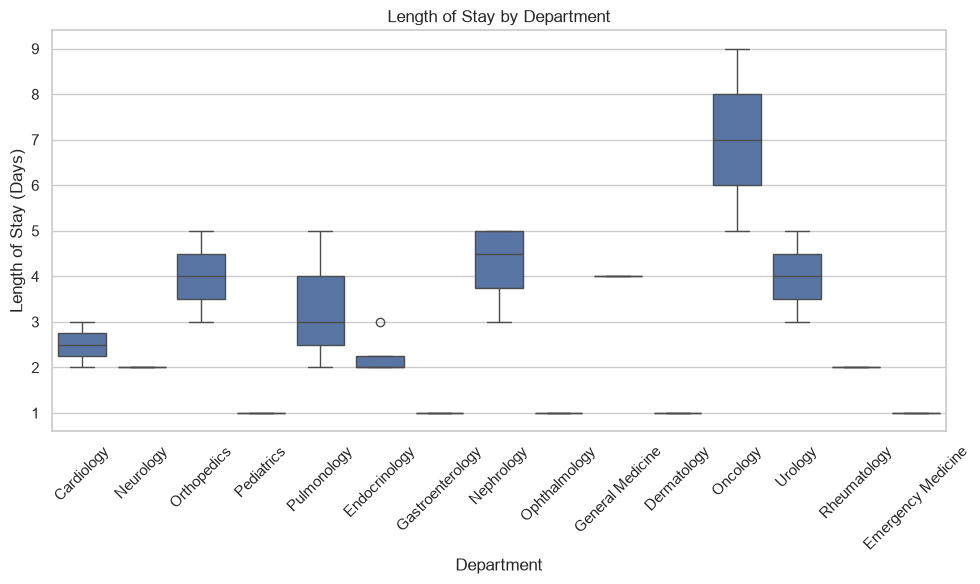

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_admissions,
    x="Department",
    y="Length_of_Stay"
)

plt.title("Length of Stay by Department")
plt.xlabel("Department")
plt.ylabel("Length of Stay (Days)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# # 9. Clinical / Treatment Analysis

# The next question is:

# ## What treatments are being performed?

# Treatment activity can reveal which clinical services are most frequently used.

# We will examine:

# - treatment frequency
# - treatment categories
# - treatment activity by department

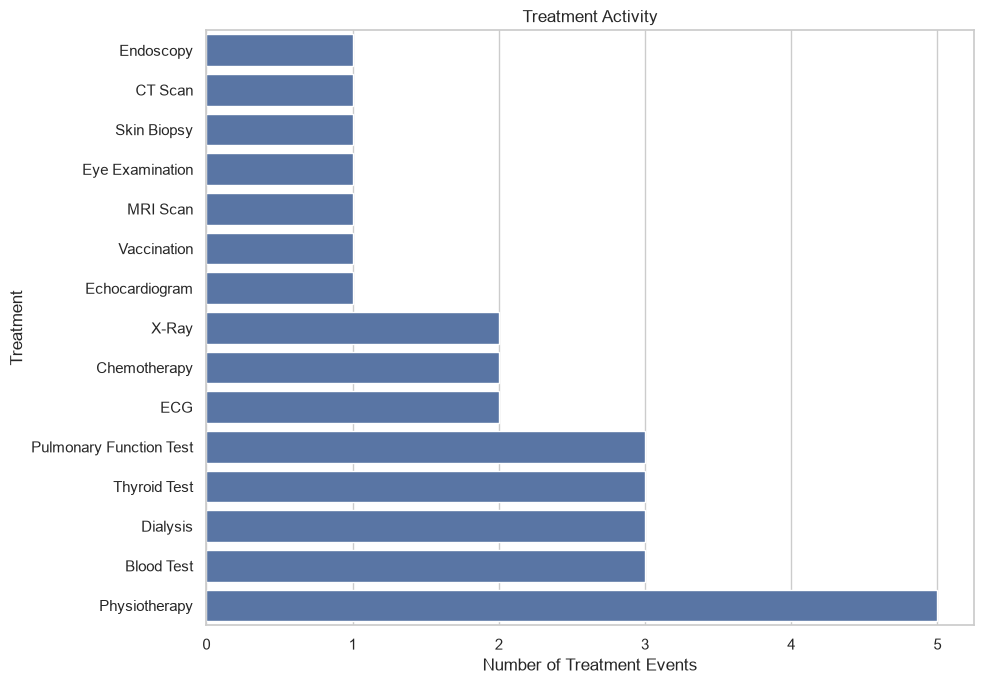

In [28]:
treatment_counts = (
    df_clinical["Treatment_Name"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    x=treatment_counts.values,
    y=treatment_counts.index
)

plt.title("Treatment Activity")
plt.xlabel("Number of Treatment Events")
plt.ylabel("Treatment")
plt.tight_layout()
plt.show()

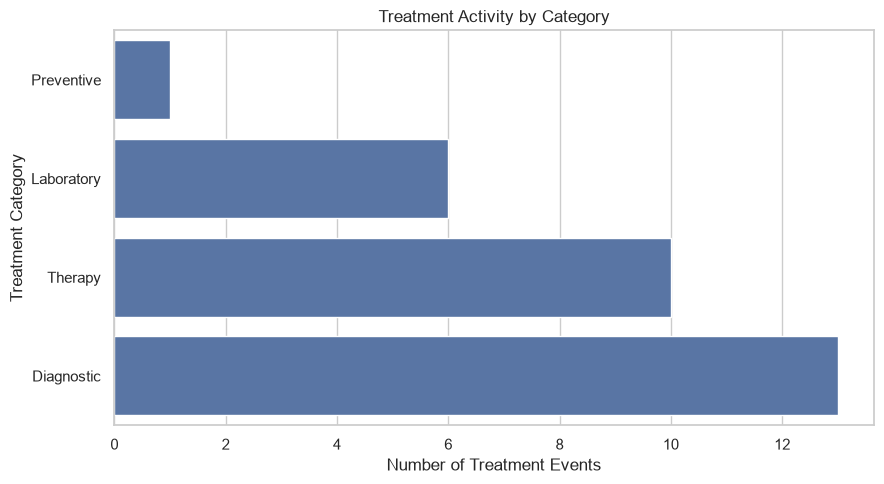

In [29]:
category_counts = (
    df_clinical["Treatment_Category"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Treatment Activity by Category")
plt.xlabel("Number of Treatment Events")
plt.ylabel("Treatment Category")
plt.tight_layout()
plt.show()

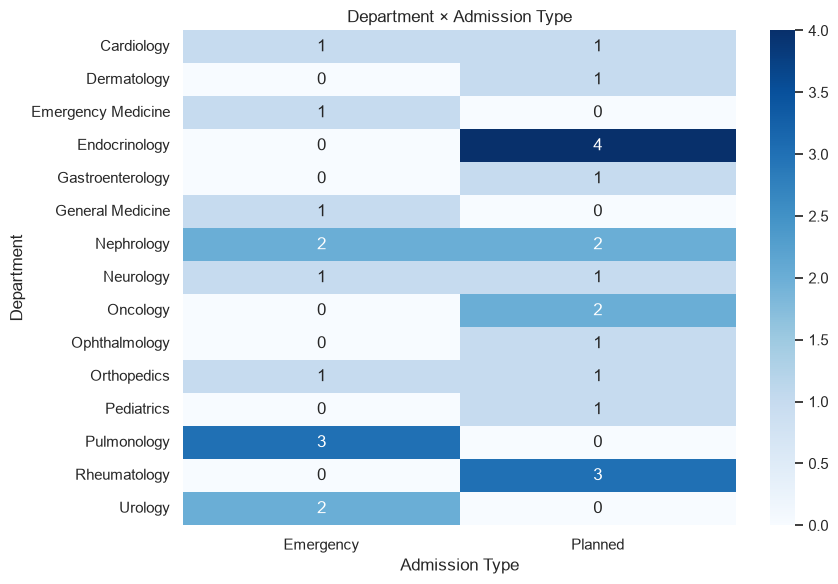

In [30]:
department_admission_heatmap = pd.crosstab(
    df_admissions["Department"],
    df_admissions["Admission_Type"]
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    department_admission_heatmap,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Department × Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [ ]:
# # 10. Financial Analysis

# The next question is:

# ## What is the financial picture?

# We will examine:

# - revenue by department
# - revenue composition
# - distribution of net billing
# - insurance coverage
# - payment status

# Financial analysis connects hospital activity with its monetary impact.

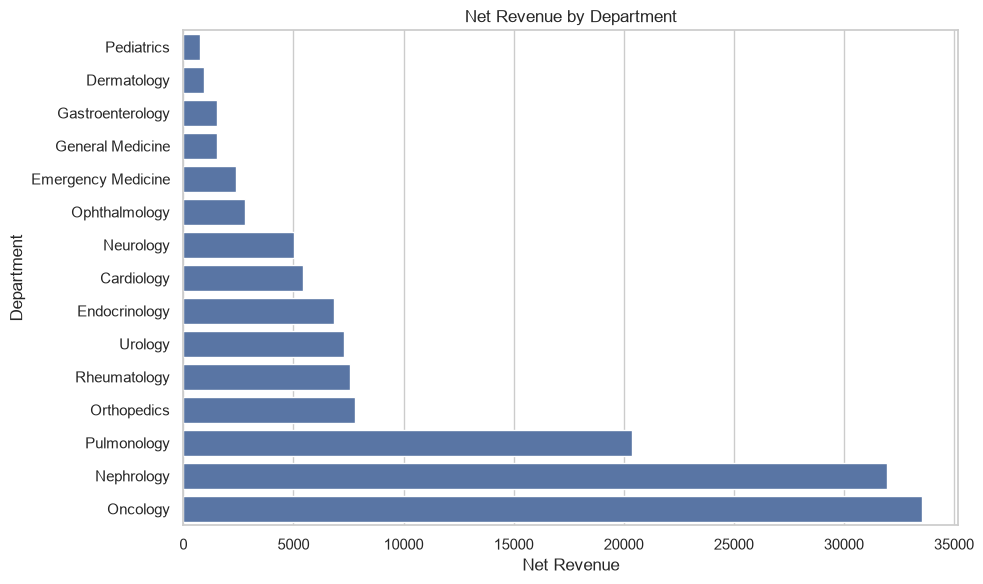

In [31]:
revenue_department = (
    df_financial
    .groupby("Department")["Net_Amount"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=revenue_department.values,
    y=revenue_department.index
)

plt.title("Net Revenue by Department")
plt.xlabel("Net Revenue")
plt.ylabel("Department")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

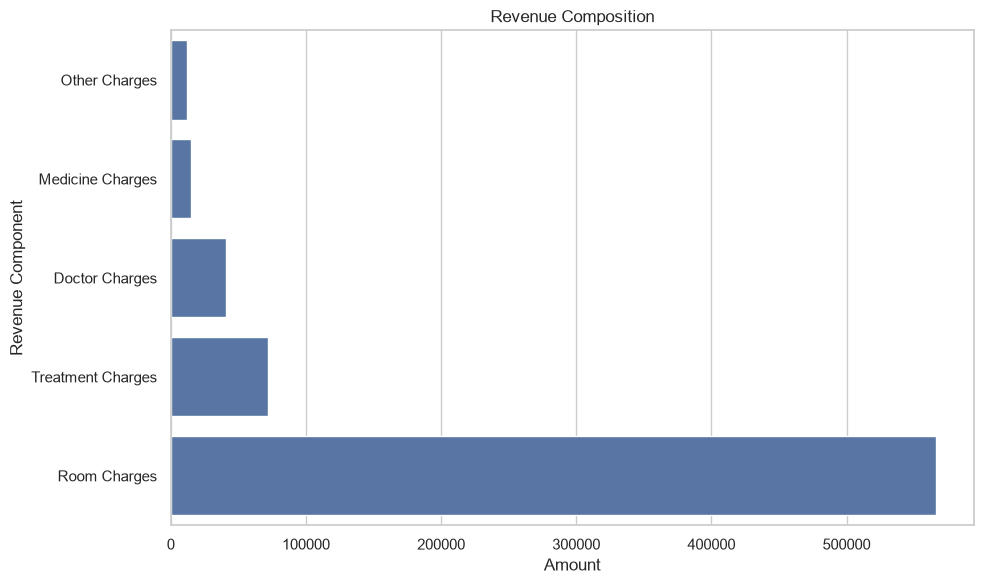

In [32]:
revenue_components = {
    "Treatment Charges": df_financial["Treatment_Charges"].sum(),
    "Medicine Charges": df_financial["Medicine_Charges"].sum(),
    "Room Charges": df_financial["Room_Charges"].sum(),
    "Doctor Charges": df_financial["Doctor_Charges"].sum(),
    "Other Charges": df_financial["Other_Charges"].sum()
}

revenue_components = (
    pd.Series(revenue_components)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=revenue_components.values,
    y=revenue_components.index
)

plt.title("Revenue Composition")
plt.xlabel("Amount")
plt.ylabel("Revenue Component")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

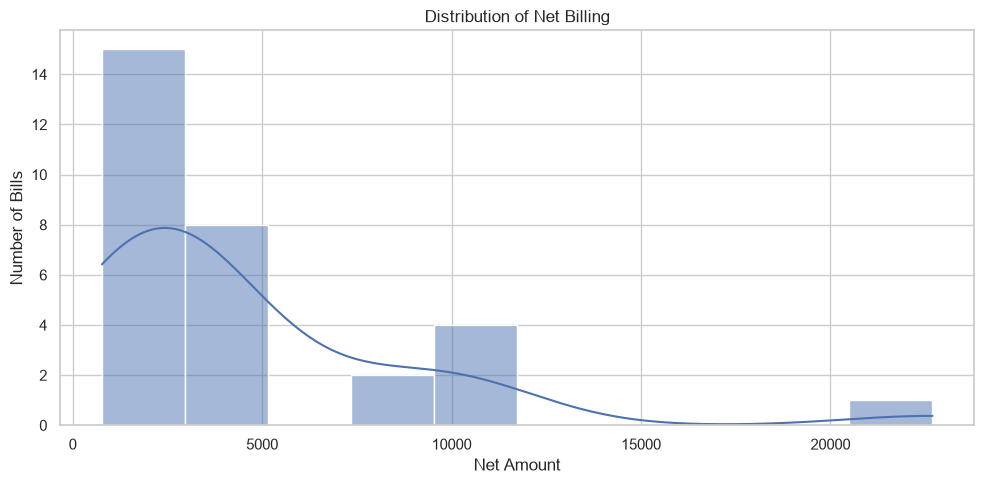

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_financial,
    x="Net_Amount",
    bins=10,
    kde=True
)

plt.title("Distribution of Net Billing")
plt.xlabel("Net Amount")
plt.ylabel("Number of Bills")
plt.tight_layout()
plt.show()

In [34]:
# Remove records where either variable is missing

financial_los = df_financial[
    [
        "Admission_ID",
        "Length_of_Stay" if "Length_of_Stay" in df_financial.columns else "Admission_ID",
        "Net_Amount"
    ]
].copy()

In [35]:
# Calculate Length of Stay in the financial dataset

df_financial["Length_of_Stay"] = (
    df_financial["Discharge_Date"]
    - df_financial["Admission_Date"]
).dt.days

financial_los = df_financial[
    ["Admission_ID", "Length_of_Stay", "Net_Amount"]
].dropna()

financial_los.head()

,Admission_ID,Length_of_Stay,Net_Amount
0,A001,3,"3,377.50"
1,A002,2,"2,580.00"
2,A003,5,"4,693.00"
3,A004,1,770.00
4,A005,5,"10,004.50"


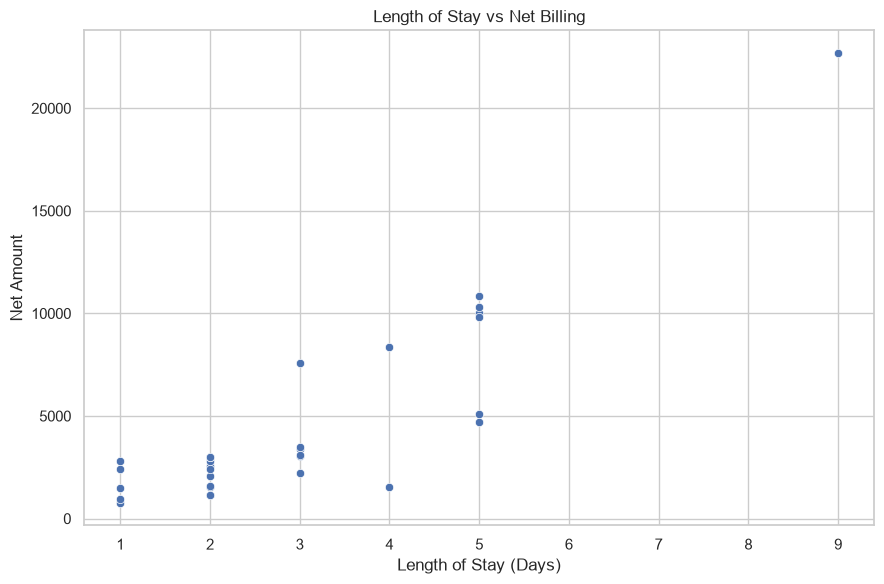

Pearson correlation: 0.882


In [36]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=financial_los,
    x="Length_of_Stay",
    y="Net_Amount"
)

plt.title("Length of Stay vs Net Billing")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Net Amount")
plt.tight_layout()
plt.show()

correlation = financial_los[
    ["Length_of_Stay", "Net_Amount"]
].corr().iloc[0, 1]

print(f"Pearson correlation: {correlation:.3f}")

In [ ]:
# # 11. Outlier Analysis

# Outliers should not automatically be treated as errors.

# An unusually high bill or unusually long stay could represent:

# - a genuine complex case
# - an exceptional treatment
# - multiple services
# - or a data-quality issue

# Therefore, Python will identify unusual observations first, 
# and they can then be investigated rather than automatically deleted.

In [37]:
Q1 = df_financial["Net_Amount"].quantile(0.25)
Q3 = df_financial["Net_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

billing_outliers = df_financial[
    (df_financial["Net_Amount"] < lower_bound) |
    (df_financial["Net_Amount"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential billing outliers:", len(billing_outliers))

display(
    billing_outliers[
        [
            "Admission_ID",
            "Department",
            "Net_Amount",
            "Payment_Status"
        ]
    ].sort_values(
        "Net_Amount",
        ascending=False
    )
)

Lower bound: -3245.6875
Upper bound: 9957.8125
Potential billing outliers: 4


,Admission_ID,Department,Net_Amount,Payment_Status
12,A013,Oncology,"22,693.00",Pending
24,A025,Oncology,"10,835.00",Pending
23,A024,Nephrology,"10,320.00",Paid
4,A005,Pulmonology,"10,004.50",Paid


In [38]:
Q1_los = df_admissions["Length_of_Stay"].quantile(0.25)
Q3_los = df_admissions["Length_of_Stay"].quantile(0.75)

IQR_los = Q3_los - Q1_los

upper_los_bound = Q3_los + 1.5 * IQR_los

los_outliers = df_admissions[
    df_admissions["Length_of_Stay"] > upper_los_bound
]

print("Potential long-stay outliers:", len(los_outliers))

display(
    los_outliers[
        [
            "Admission_ID",
            "Department",
            "Length_of_Stay"
        ]
    ].sort_values(
        "Length_of_Stay",
        ascending=False
    )
)

Potential long-stay outliers: 1


,Admission_ID,Department,Length_of_Stay
12,A013,Oncology,9


In [ ]:
# # 12. Key Business Metrics

# Now we convert the exploratory analysis into a concise set of metrics.

# These are not intended to replace the Excel or Power BI dashboards.

# Instead, they provide a numerical summary of what Python discovered.

In [39]:
# Key metrics

total_patients = df_admissions["Patient_ID"].nunique()
total_admissions = df_admissions["Admission_ID"].nunique()

average_los = df_admissions["Length_of_Stay"].mean()
median_los = df_admissions["Length_of_Stay"].median()

gross_revenue = df_financial["Gross_Amount"].sum()
net_revenue = df_financial["Net_Amount"].sum()

insurance_coverage = df_financial["Insurance_Coverage"].sum()

insurance_coverage_pct = (
    insurance_coverage / gross_revenue * 100
    if gross_revenue != 0
    else 0
)

summary = pd.DataFrame({
    "Metric": [
        "Total Patients",
        "Total Admissions",
        "Average Length of Stay",
        "Median Length of Stay",
        "Gross Revenue",
        "Net Revenue",
        "Insurance Coverage",
        "Insurance Coverage %"
    ],
    "Value": [
        total_patients,
        total_admissions,
        average_los,
        median_los,
        gross_revenue,
        net_revenue,
        insurance_coverage,
        insurance_coverage_pct
    ]
})

summary

,Metric,Value
0,Total Patients,20.00
1,Total Admissions,30.00
2,Average Length of Stay,3.00
3,Median Length of Stay,2.50
4,Gross Revenue,"705,400.00"
5,Net Revenue,"135,800.50"
6,Insurance Coverage,"550,504.50"
7,Insurance Coverage %,78.04


In [ ]:
# # 13. Automated Analytical Observations

# The purpose of this section is to turn charts and statistics into actual observations.

# The notebook should not invent conclusions.

# Instead, the observations below are calculated directly from the dataset.

In [40]:
# Automatically calculate major patterns

top_department = (
    df_admissions["Department"]
    .value_counts()
    .idxmax()
)

top_department_count = (
    df_admissions["Department"]
    .value_counts()
    .max()
)

top_admission_type = (
    df_admissions["Admission_Type"]
    .value_counts()
    .idxmax()
)

top_treatment = (
    df_clinical["Treatment_Name"]
    .value_counts()
    .idxmax()
)

highest_revenue_department = (
    df_financial
    .groupby("Department")["Net_Amount"]
    .sum()
    .idxmax()
)

highest_revenue_value = (
    df_financial
    .groupby("Department")["Net_Amount"]
    .sum()
    .max()
)

print("KEY OBSERVATIONS")
print("=" * 60)

print(
    f"1. Highest admission volume: {top_department} "
    f"({top_department_count} admissions)."
)

print(
    f"2. Most common admission type: {top_admission_type}."
)

print(
    f"3. Most frequently recorded treatment: {top_treatment}."
)

print(
    f"4. Highest net revenue department: "
    f"{highest_revenue_department} "
    f"({highest_revenue_value:,.2f})."
)

print(
    f"5. Average length of stay: {average_los:.2f} days."
)

print(
    f"6. Median length of stay: {median_los:.2f} days."
)

print(
    f"7. Length of stay vs net billing correlation: "
    f"{correlation:.3f}."
)

KEY OBSERVATIONS
1. Highest admission volume: Endocrinology (4 admissions).
2. Most common admission type: Planned.
3. Most frequently recorded treatment: Physiotherapy.
4. Highest net revenue department: Oncology (33,528.00).
5. Average length of stay: 3.00 days.
6. Median length of stay: 2.50 days.
7. Length of stay vs net billing correlation: 0.882.


In [ ]:
# # 14. Analytical Interpretation

# The Python analysis provides several layers of insight:

# ### Patient profile
# The demographic analysis describes the age and gender composition of the patient population.

# ### Hospital utilization
# Department and admission-type analysis shows how hospital activity is distributed.

# ### Operational performance
# Length-of-stay analysis highlights typical hospitalization duration and potential unusually long stays.

# ### Clinical activity
# Treatment analysis identifies frequently performed treatments and clinical categories.

# ### Financial performance
# Revenue analysis shows how financial activity is distributed across departments and billing components.

# ### Relationships
# Correlation and scatter analysis allows us to investigate whether operational variables, 
# such as length of stay, are associated with financial outcomes.

# ### Data quality
# Validation checks identify missing values, duplicates, invalid dates, 
# and statistical outliers that should be investigated before drawing conclusions.

# Python therefore serves as the exploratory and analytical layer of the project, 
# while Excel and Power BI serve as interactive reporting layers.

In [ ]:
# # 15. Conclusion

# The complete analytical workflow can be summarized as:

# SQL Server
# → structured relational data

# Python
# → inspection, validation, statistical analysis and discovery

# Excel
# → interactive analytical dashboard

# Power BI
# → interactive business intelligence reporting

# The tools are therefore not being used to perform the same task.

# Each tool contributes a different layer to the overall data analytics workflow.